# Exploratory data analysis: Spotify tracks

This notebook explores the raw dataset (~114k tracks, 114 genres) and motivates every
modelling decision in the recommender:

1. **Data quality**: what has to be cleaned before recommending anything
2. **Audio feature distributions**: why features are quantile-transformed
3. **Feature correlations**: redundancy between features
4. **Genres**: how distinct genres sound, and how they overlap
5. **Popularity**: why popularity is *not* used as a similarity feature

Run `music-rec build` first to download the data.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from music_recommender.config import AUDIO_FEATURES, PROFILE_FEATURES, RAW_PATH
from music_recommender.data import clean, load_raw

pd.set_option("display.precision", 3)
BLUE, ORANGE, INK_2, GRID, SURFACE = "#2a78d6", "#eb6834", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "axes.titlelocation": "left",
        "axes.titlesize": 11,
        "figure.dpi": 110,
    }
)
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#2a78d6", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])

raw = load_raw(RAW_PATH)
raw.head()

,track_id,artists,album_name,track_name,popularity,explicit,track_genre,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,False,acoustic,0.676,0.461,-6.746,0.143,0.032,1.010e-06,0.358,0.715,87.917,230666
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,False,acoustic,0.420,0.166,-17.235,0.076,0.924,5.560e-06,0.101,0.267,77.489,149610
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,False,acoustic,0.438,0.359,-9.734,0.056,0.210,0.000e+00,0.117,0.120,76.332,210826
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,False,acoustic,0.266,0.060,-18.515,0.036,0.905,7.070e-05,0.132,0.143,181.740,201933
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,False,acoustic,0.618,0.443,-9.681,0.053,0.469,0.000e+00,0.083,0.167,119.949,198853


## 1. Data quality

In [2]:
n_ids = raw.track_id.nunique()
multi_genre = (raw.groupby("track_id").track_genre.nunique() > 1).sum()
print(f"rows: {len(raw):,} | unique track_ids: {n_ids:,} | genres: {raw.track_genre.nunique()}")
print(f"track_ids listed under more than one genre: {multi_genre:,}")
print(f"tracks with tempo == 0 (failed audio analysis): {(raw.tempo == 0).sum()}")
print(f"tracks shorter than 30s: {(raw.duration_ms < 30_000).sum()}")
print(
    f"tracks with popularity == 0: {(raw.popularity == 0).sum():,} ({(raw.popularity == 0).mean():.0%})"
)

rows: 114,000 | unique track_ids: 89,741 | genres: 114
track_ids listed under more than one genre: 16,299
tracks with tempo == 0 (failed audio analysis): 157
tracks shorter than 30s: 17
tracks with popularity == 0: 16,020 (14%)


The dataset was collected by sampling ~1,000 tracks *per genre*, so a song tagged with
several genres appears several times. Left as-is, a recommender would happily recommend
the seed song back to the user. The same song is also often published several times
(single, album, deluxe edition). `clean()` resolves both and keeps an audit trail:

In [3]:
tracks, report = clean(raw)
report.to_frame()

,step,rows,rows_removed
0,raw rows,114000,0
1,drop rows with missing title/artist,113999,1
2,drop failed audio analysis / non-song durations,113677,322
3,merge duplicate track_ids (multi-genre listings),89432,24245
4,merge re-releases of the same song,80911,8521


In [4]:
tracks.genres.map(len).value_counts().sort_index().rename_axis("genres per song").to_frame("songs")

,songs
genres per song,
1,67514
2,9761
3,2335
4,939
5,257
6,83
7,20
8,1
9,1


After cleaning, **~29% of rows were removed**, and ~17% of songs carry more than one genre label. Those
multi-genre songs are what make it possible to learn which genres are related (section 4).

## 2. Audio feature distributions

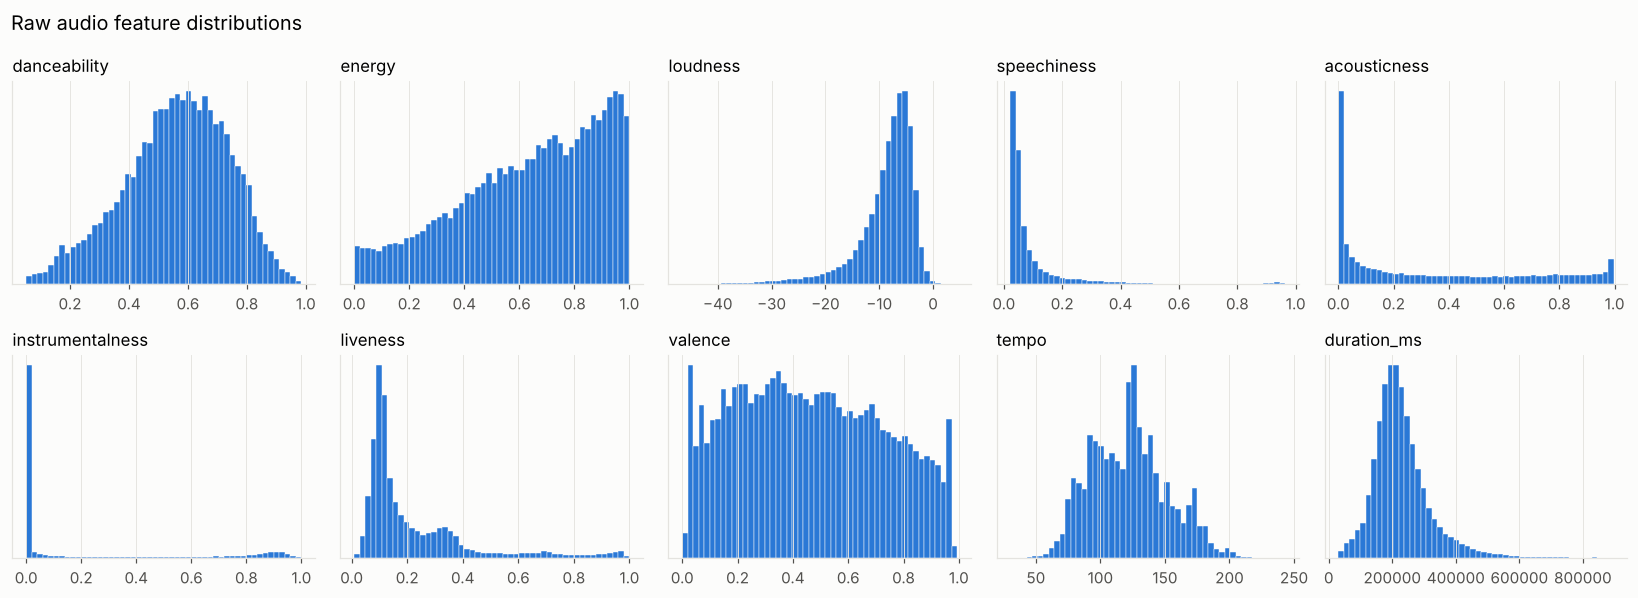

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5.5))
for ax, col in zip(axes.flat, AUDIO_FEATURES, strict=True):
    ax.hist(tracks[col], bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
    ax.set_title(col)
    ax.set_yticks([])
fig.suptitle("Raw audio feature distributions", x=0.01, ha="left", fontsize=13)
fig.tight_layout()

In [6]:
tracks[AUDIO_FEATURES].skew().sort_values(ascending=False).to_frame("skewness")

,skewness
speechiness,4.485
liveness,2.036
duration_ms,1.484
instrumentalness,1.472
acousticness,0.650
tempo,0.278
valence,0.152
danceability,-0.360
energy,-0.559
loudness,-1.917


Speechiness, instrumentalness, liveness and duration are heavily skewed, and loudness has a long
left tail. With plain z-scoring, a few extreme tracks would dominate cosine distances. The feature
pipeline therefore uses a **quantile transform to a standard normal**, which compares tracks by
*rank* on each feature and is robust to outliers.

## 3. Feature correlations

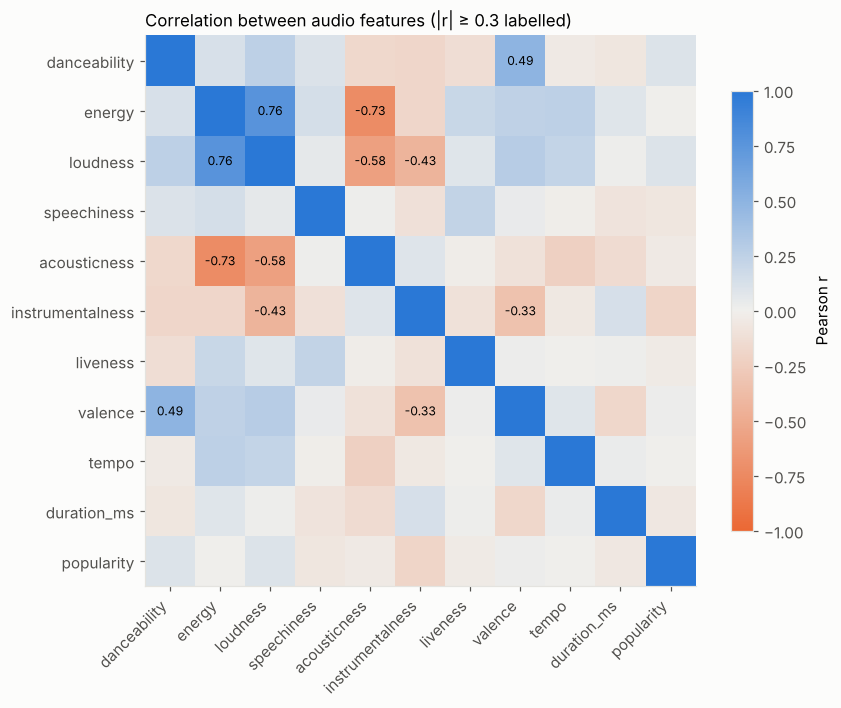

In [7]:
corr = tracks[AUDIO_FEATURES + ["popularity"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if abs(corr.iloc[i, j]) >= 0.3 and i != j:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation between audio features (|r| ≥ 0.3 labelled)")
fig.tight_layout()

Energy, loudness and acousticness form a strongly correlated cluster (energy-loudness r≈0.76,
energy-acousticness r≈-0.73). This "intensity" axis is effectively counted three times in the
distance. I kept all three because each still carries some unique signal (e.g. a quiet but
electronic track), and audio features alone already beat random by a wide margin in the
evaluation (HitRate@10 of 0.13 vs 0.003).
Popularity is almost uncorrelated with every audio feature, so it says nothing about how a song
*sounds*.

## 4. Genres: how distinct are they?

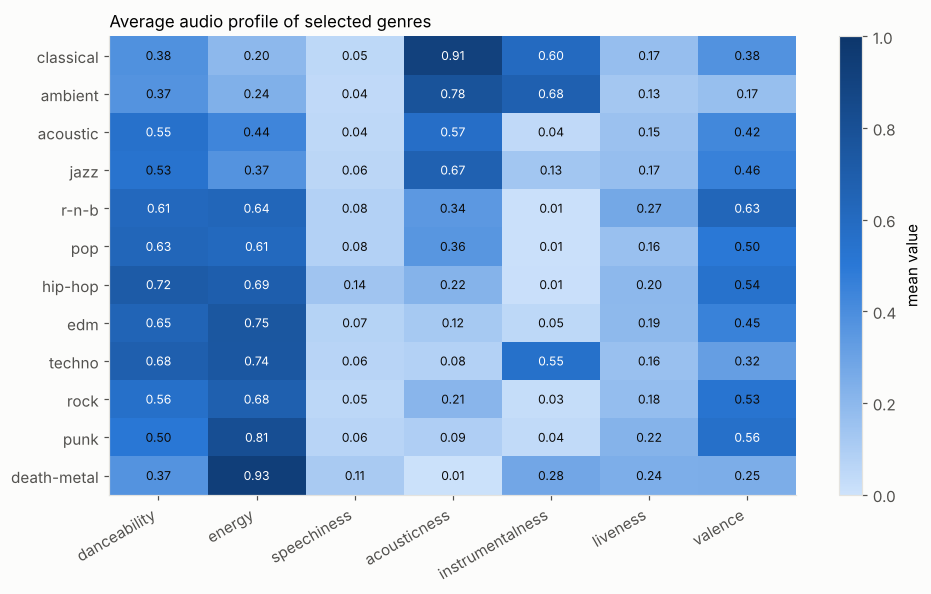

In [8]:
sample_genres = [
    "classical",
    "ambient",
    "acoustic",
    "jazz",
    "r-n-b",
    "pop",
    "hip-hop",
    "edm",
    "techno",
    "rock",
    "punk",
    "death-metal",
]
exploded = tracks.explode("genres")
profile = exploded[exploded.genres.isin(sample_genres)].groupby("genres")[PROFILE_FEATURES].mean()
profile = profile.loc[sample_genres]

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(profile, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(PROFILE_FEATURES)), PROFILE_FEATURES, rotation=30, ha="right")
ax.set_yticks(range(len(profile)), profile.index)
ax.grid(False)
for i in range(profile.shape[0]):
    for j in range(profile.shape[1]):
        v = profile.iloc[i, j]
        ax.text(
            j,
            i,
            f"{v:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if v > 0.55 else "#0b0b0b",
        )
fig.colorbar(im, ax=ax, label="mean value")
ax.set_title("Average audio profile of selected genres")
fig.tight_layout()

Genres have clearly different audio fingerprints (classical and ambient are acoustic and
instrumental, death-metal is all energy, hip-hop has the highest speechiness), which is why
audio features carry real signal. But neighbouring genres (pop vs. r-n-b, edm vs. techno) overlap a
lot, which is why audio *alone* struggles and genre information adds so much in the evaluation.

### Which genres co-occur on the same song?

In [9]:
from collections import Counter
from itertools import combinations

pairs = Counter(p for gs in tracks.genres if len(gs) > 1 for p in combinations(sorted(gs), 2))
pd.DataFrame(pairs.most_common(15), columns=["genre pair", "songs"])

,genre pair,songs
0,"(singer-songwriter, songwriter)",788
1,"(dub, dubstep)",676
2,"(punk, punk-rock)",551
3,"(indie, indie-pop)",464
4,"(reggae, reggaeton)",432
5,"(alt-rock, alternative)",430
6,"(latino, reggaeton)",427
7,"(edm, house)",397
8,"(latino, reggae)",326
9,"(minimal-techno, techno)",318


Co-occurrence shows genre structure that the flat labels hide: `singer-songwriter`/`songwriter`,
`punk`/`punk-rock`, `indie`/`indie-pop`, `edm`/`house` and `minimal-techno`/`techno` are
near-synonyms. The recommender can turn this into a **genre embedding** (positive PMI on the
co-occurrence matrix + truncated SVD) so related genres sit close together in vector space.

Some pairs look wrong, though: `dub`/`dubstep`, `reggae`/`reggaeton` and `brazil`/`gospel` are
musically quite different. They're probably an artefact of how the dataset was collected (genre
searches that match on similar names). That noise is a plausible reason the learned embedding
ends up *losing* to plain one-hot genres in the evaluation.

## 5. Popularity

median popularity: 35; share with popularity 0: 6%


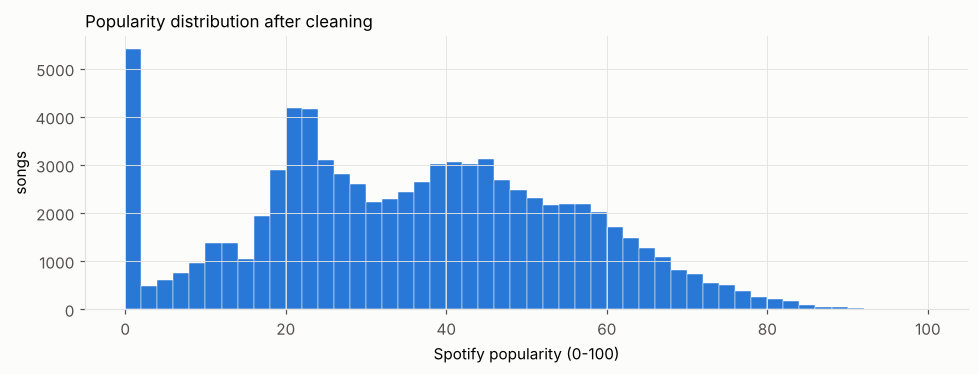

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(tracks.popularity, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
ax.set_xlabel("Spotify popularity (0-100)")
ax.set_ylabel("songs")
ax.set_title("Popularity distribution after cleaning")
fig.tight_layout()
print(
    f"median popularity: {tracks.popularity.median():.0f}; share with popularity 0: {(tracks.popularity == 0).mean():.0%}"
)

Popularity is bimodal: a spike at 0 (about 6% of songs after cleaning) and a broad hump around
20-60. Using it as a similarity feature would mix "sounds alike" with "is famous", so it is
deliberately left out of the vectors and offered only as an optional *filter* in the app. The
evaluation also tracks average recommended popularity to make popularity bias visible: the
content model recommends tracks with a mean popularity of about 35, versus 97 for the
popularity baseline.

## Takeaways → modelling decisions

| Finding | Decision |
|---|---|
| 24k duplicate track_ids, 8.5k re-releases | Merge into one row per song, union genres |
| Heavily skewed audio features | Quantile transform → standard normal |
| Genres have distinct audio fingerprints but neighbours overlap | Combine audio + genre blocks with a tunable weight |
| 17% of songs are multi-genre | Learn a genre embedding from co-occurrence (and compare against one-hot) |
| Popularity unrelated to sound | Keep out of the vectors; use only as a filter and a bias metric |